# Análisis exploratorio de los datos — Gemelo Digital de Aruba

Antes de pasar a los modelos queremos entender bien los datos. Primero revisamos las lecturas meteorológicas que nos dio la asignatura, después los datos externos que hemos añadido y, por último, comparamos las lecturas simuladas con datos reales de Aruba.

Las figuras y tablas se guardan en `resultados/04_eda/` para poder usarlas en la memoria.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# El notebook está dentro de EDA/, así que la raíz del repo es la carpeta de arriba
RAIZ = Path("..")
ENR = RAIZ / "DatosEnriquecimiento"
LECTURAS = RAIZ / "ETL" / "transformado" / "db_meteorologica_sinDesfase.csv.gz"

FIGURAS = RAIZ / "resultados" / "04_eda" / "figuras"
TABLAS = RAIZ / "resultados" / "04_eda" / "tablas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

AZUL = "#2a78d6"
NARANJA = "#eb6834"

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=150)
    plt.show()

estaciones = pd.read_csv(ENR / "estaciones" / "aruba_estaciones_enriquecidas.csv")
NOMBRES = dict(zip(estaciones["id"], estaciones["name"]))

## 1. Las lecturas meteorológicas originales

Usamos el fichero ya corregido por el notebook del desfase. Son 12 estaciones con una lectura cada 5 minutos. Los datos son simulados.

In [2]:
lect = pd.read_csv(LECTURAS)
lect["timestamp"] = pd.to_datetime(lect["timestamp"], utc=True)
lect["estacion"] = lect["station_id"].map(NOMBRES)

VARIABLES = ["temperature_c", "humidity_pct", "wind_speed_kmh", "wind_direction_deg",
             "pressure_hpa", "precipitation_mm", "visibility_km", "uv_index"]

# Para ver los huecos comparamos los instantes que hay con los que debería haber
instantes = lect["timestamp"].drop_duplicates().sort_values()
esperados = pd.date_range(instantes.min(), instantes.max(), freq="5min")
faltan = esperados.difference(instantes)

resumen = pd.Series({
    "Filas": len(lect),
    "Estaciones": lect["station_id"].nunique(),
    "Desde": instantes.min(),
    "Hasta": instantes.max(),
    "Duplicados": lect.duplicated(["station_id", "timestamp"]).sum(),
    "Valores nulos": lect[VARIABLES].isna().sum().sum(),
    "Días sin datos": round(len(faltan) / 288, 1),
})
resumen.to_csv(TABLAS / "01_resumen_lecturas.csv", header=["valor"])
resumen

Filas                               1287072
Estaciones                               12
Desde             2025-09-01 12:00:00+00:00
Hasta             2026-09-17 21:55:00+00:00
Duplicados                                0
Valores nulos                             0
Días sin datos                          9.0
dtype: object

In [3]:
# Agrupamos los instantes que faltan en tramos seguidos
faltan = pd.Series(faltan)
tramo = (faltan.diff() != pd.Timedelta("5min")).cumsum()
huecos = faltan.groupby(tramo).agg(["min", "max", "count"])
huecos.columns = ["desde", "hasta", "lecturas"]
huecos.to_csv(TABLAS / "01_huecos.csv", index=False)
huecos

,desde,hasta,lecturas
1,2026-01-04 00:00:00+00:00,2026-01-11 11:55:00+00:00,2160
2,2026-03-30 22:00:00+00:00,2026-04-01 09:55:00+00:00,432


No hay duplicados ni nulos, porque ya se limpiaron en el ETL. Quedan dos huecos sin ninguna lectura: una semana a principios de enero y un día y medio entre marzo y abril. En el dataset final esas filas aparecen con `hay_lectura = 0`.

In [4]:
estadisticas = lect[VARIABLES].describe().T.round(2)
estadisticas.to_csv(TABLAS / "01_estadisticas_variables.csv")
estadisticas

,count,mean,std,min,25%,50%,75%,max
temperature_c,1287072.0,28.34,2.86,20.0,26.0,28.5,30.7,35.5
humidity_pct,1287072.0,76.99,6.91,62.3,70.8,77.1,81.9,100.0
wind_speed_kmh,1287072.0,23.94,3.77,12.2,21.4,23.7,25.9,57.4
wind_direction_deg,1287072.0,45.05,6.06,14.3,41.6,45.0,48.5,75.8
pressure_hpa,1287072.0,1014.38,1.34,997.6,1013.4,1014.3,1015.5,1017.0
precipitation_mm,1287072.0,0.01,0.23,0.0,0.0,0.0,0.0,20.7
visibility_km,1287072.0,11.99,0.35,0.5,11.8,12.0,12.2,13.4
uv_index,1287072.0,2.54,3.10,0.0,0.0,0.0,5.7,9.4


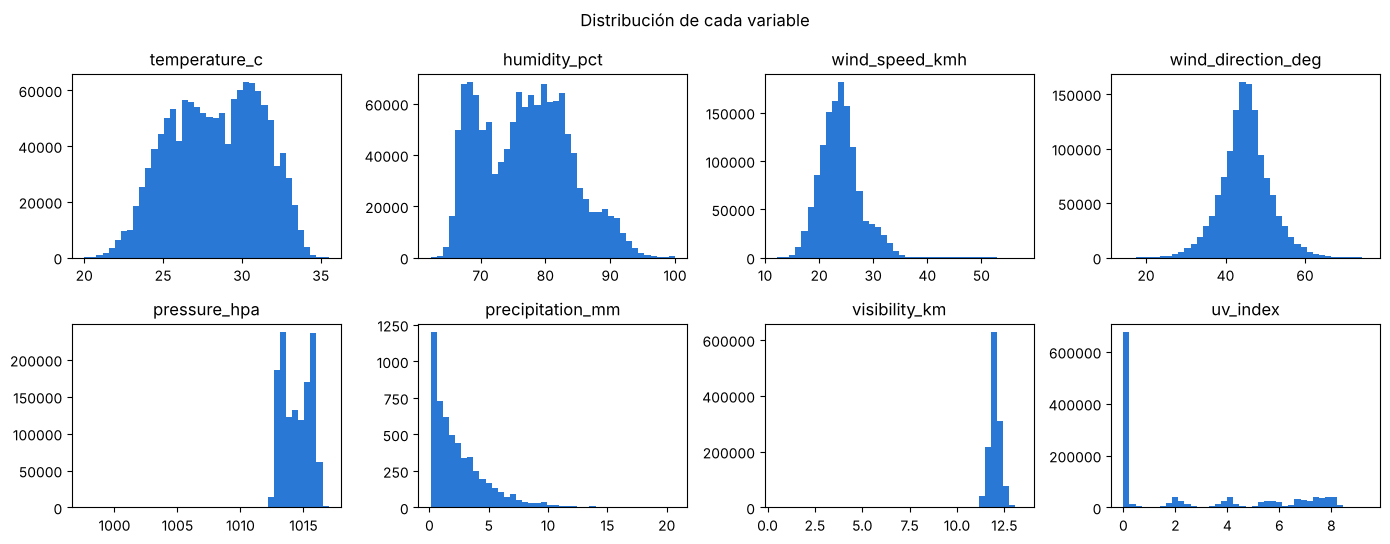

In [5]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 5.5))
for eje, var in zip(ejes.flat, VARIABLES):
    datos = lect[var]
    if var == "precipitation_mm":
        datos = datos[datos > 0]   # casi siempre es 0, miramos solo cuando llueve
    eje.hist(datos, bins=40, color=AZUL)
    eje.set_title(var)
fig.suptitle("Distribución de cada variable")
guardar(fig, "01_distribuciones")

Es el clima de una isla tropical: temperatura media de 28 °C, viento casi siempre del noreste (unos 45°, el alisio) y prácticamente sin lluvia, ya que solo llueve en el 0,4 % de las lecturas. El UV tiene muchos ceros porque incluye las noches.

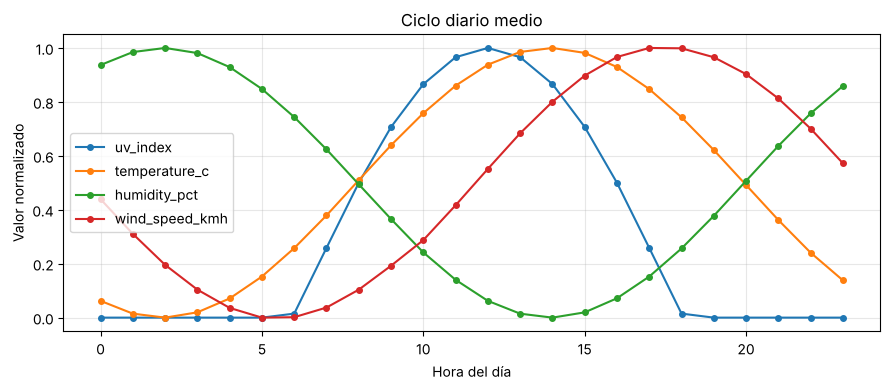

In [6]:
perfil = lect.groupby(lect["timestamp"].dt.hour)[["uv_index", "temperature_c", "humidity_pct", "wind_speed_kmh"]].mean()
# Normalizamos entre 0 y 1 para poder ver las cuatro en el mismo gráfico
perfil_norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())

fig, eje = plt.subplots(figsize=(9, 4))
perfil_norm.plot(ax=eje, marker="o", markersize=4)
eje.set_xlabel("Hora del día")
eje.set_ylabel("Valor normalizado")
eje.set_title("Ciclo diario medio")
eje.grid(alpha=0.3)
guardar(fig, "01_ciclo_diario")

Con este gráfico comprobamos que la corrección del desfase está bien: el UV es máximo a mediodía y la temperatura un par de horas después, como pasa en la realidad. La humedad va al revés que la temperatura y el viento sube durante el día hasta el final de la tarde.

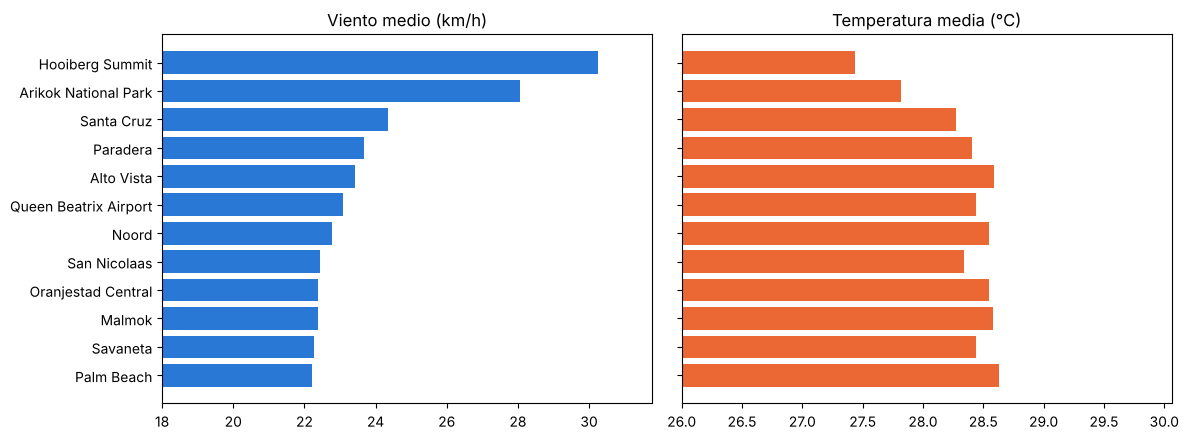

In [7]:
por_estacion = lect.groupby("estacion")[["temperature_c", "wind_speed_kmh", "humidity_pct"]].mean().round(2)
por_estacion = por_estacion.sort_values("wind_speed_kmh")
por_estacion.to_csv(TABLAS / "01_medias_por_estacion.csv")

fig, (e1, e2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
e1.barh(por_estacion.index, por_estacion["wind_speed_kmh"], color=AZUL)
e1.set_title("Viento medio (km/h)")
e1.set_xlim(18, None)
e2.barh(por_estacion.index, por_estacion["temperature_c"], color=NARANJA)
e2.set_title("Temperatura media (°C)")
e2.set_xlim(26, None)
guardar(fig, "01_medias_por_estacion")

Las estaciones son muy parecidas salvo Hooiberg Summit y Arikok National Park, que están más altas (165 y 120 m): allí hace algo menos de calor y sopla bastante más viento, unos 30 y 28 km/h frente a los 22–24 km/h del resto. San Nicolaas, la que usamos para el target, está en la media.

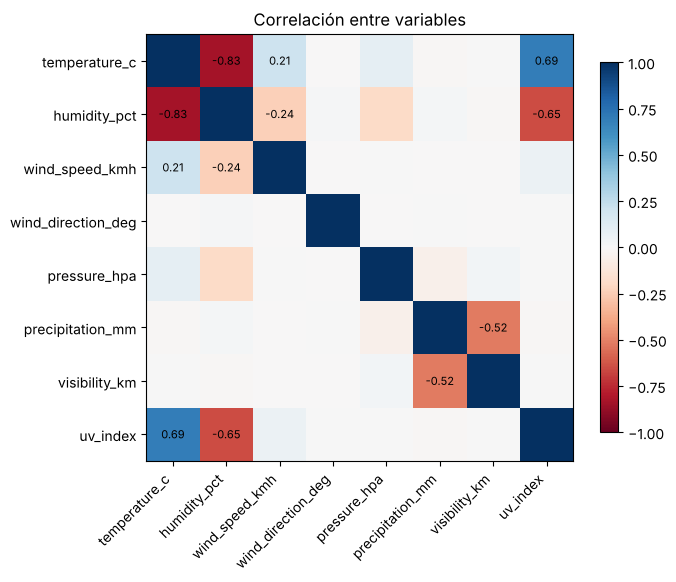

In [8]:
corr = lect[VARIABLES].corr()
corr.round(3).to_csv(TABLAS / "01_correlaciones.csv")

fig, eje = plt.subplots(figsize=(7, 6))
im = eje.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
eje.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=45, ha="right")
eje.set_yticks(range(len(VARIABLES)), VARIABLES)
for i in range(len(VARIABLES)):
    for j in range(len(VARIABLES)):
        if i != j and abs(corr.iloc[i, j]) >= 0.2:
            eje.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=eje, shrink=0.8)
eje.set_title("Correlación entre variables")
guardar(fig, "01_correlaciones")

Lo esperable: temperatura y humedad van en sentido contrario (−0,83) y el UV sigue a la temperatura (0,69). El viento casi no se relaciona con nada, así que para predecir la eólica pesará más su propio comportamiento reciente que el resto de variables.

## 2. Los datos de enriquecimiento

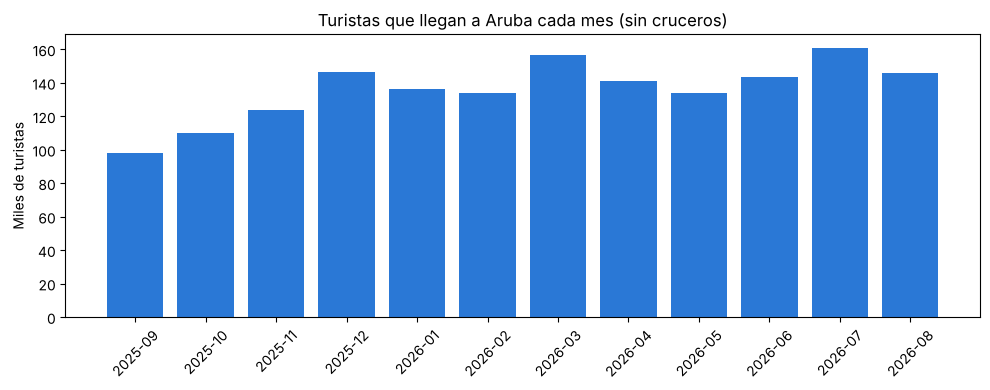

,mes,stopover,var_pct,cruceros_pasajeros
0,2025-09,97778.0,2.6,NaN
1,2025-10,109990.0,5.7,58320.0
2,2025-11,123831.0,15.9,98980.0
3,2025-12,146515.0,14.3,160420.0
4,2026-01,136578.0,9.4,138059.0
5,2026-02,133992.0,NaN,118681.0
6,2026-03,156773.0,8.8,119702.0
7,2026-04,141135.0,11.6,86466.0
8,2026-05,133680.0,14.1,42118.0
9,2026-06,143343.0,13.4,46142.0


In [9]:
turismo = pd.read_csv(ENR / "turismo" / "aruba_turismo_mensual.csv").dropna(subset=["stopover"])

fig, eje = plt.subplots(figsize=(10, 4))
eje.bar(turismo["mes"], turismo["stopover"] / 1000, color=AZUL)
eje.set_ylabel("Miles de turistas")
eje.set_title("Turistas que llegan a Aruba cada mes (sin cruceros)")
eje.tick_params(axis="x", rotation=45)
guardar(fig, "02_turismo_mensual")
turismo[["mes", "stopover", "var_pct", "cruceros_pasajeros"]]

Llegan entre 98.000 y 161.000 turistas al mes, y todos los meses son más que el año anterior. No afecta a la generación renovable, pero lo tenemos para cuando metamos la demanda en el gemelo digital.

In [10]:
calendario = pd.read_csv(ENR / "calendario" / "aruba_calendario_5min.csv", dtype={"festivo_nombre": str})
festivos = calendario.loc[calendario["es_festivo"] == 1, ["fecha_local", "festivo_nombre"]].drop_duplicates()
festivos.to_csv(TABLAS / "02_festivos.csv", index=False)
festivos

,fecha_local,festivo_nombre
33120,2025-12-25,Christmas Day (Pasco di Nacemento)
33408,2025-12-26,Boxing Day (Di dos dia di Pasco di Nacemento)
35136,2026-01-01,New Year's Day (Aña Nobo)
42048,2026-01-25,Betico Croes Day (Dia di Betico)
48384,2026-02-16,Carnival Monday (Dialuna di Carnaval)
57024,2026-03-18,National Anthem and Flag Day (Dia di Himno y B...
61632,2026-04-03,Good Friday (Bierna Santo)
62496,2026-04-06,Easter Monday (Di dos dia di Pasco)
68544,2026-04-27,King's Day (Dia di Rey)
69696,2026-05-01,Labour Day (Dia di Obrero)


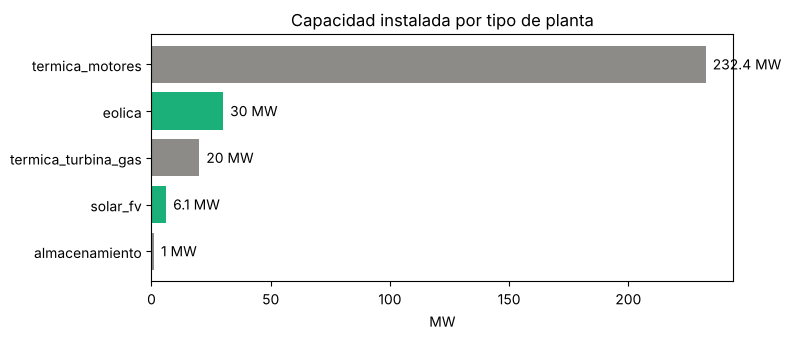

In [11]:
sistema = pd.read_csv(ENR / "sistema_electrico" / "aruba_sistema_electrico.csv")
capacidad = sistema.groupby("tipo")["capacidad_mw"].sum().sort_values()
capacidad.to_csv(TABLAS / "02_capacidad_por_tipo.csv")

fig, eje = plt.subplots(figsize=(8, 3.5))
colores = ["#1baf7a" if t in ("eolica", "solar_fv") else "#8c8b87" for t in capacidad.index]
eje.barh(capacidad.index, capacidad.values, color=colores)
for y, valor in enumerate(capacidad.values):
    eje.text(valor + 3, y, f"{valor:g} MW", va="center")
eje.set_xlabel("MW")
eje.set_title("Capacidad instalada por tipo de planta")
guardar(fig, "02_capacidad_instalada")

De los casi 290 MW de la isla, solo 36,1 MW son renovables (30 MW eólicos y 6,1 MW solares). Ni a pleno rendimiento cubrirían un tercio de la demanda media prevista para 2026 (121 MW), así que el despacho siempre va a necesitar los motores. Lo que aporta predecir bien la renovable es saber cuánto hay que pedirles en cada momento.

## 3. Datos simulados frente a datos reales

Para saber cuánto se parecen las lecturas simuladas al clima real, las cruzamos con los datos de Open-Meteo para las mismas estaciones y fechas. Open-Meteo es un modelo meteorológico, no una medida directa, pero es lo más cercano a datos reales que tenemos para todo el año.

In [12]:
real = pd.read_csv(ENR / "clima_solar" / "aruba_meteo_real_5min.csv.gz")
real = real[real["station_id"] != "VADER_PIET"]

# Cruzamos por estación y por el timestamp en texto
lect["clave"] = lect["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
cruce = lect.merge(real, left_on=["station_id", "clave"], right_on=["station_id", "timestamp"],
                   suffixes=("", "_real"))
print("Lecturas cruzadas:", len(cruce))

PARES = [("temperature_c", "temperature_2m", "Temperatura (°C)"),
         ("humidity_pct", "relative_humidity_2m", "Humedad (%)"),
         ("wind_speed_kmh", "wind_speed_10m", "Viento a 10 m (km/h)"),
         ("pressure_hpa", "surface_pressure", "Presión (hPa)")]

filas = []
for sim, rea, nombre in PARES:
    filas.append({"variable": nombre,
                  "media simulada": cruce[sim].mean(),
                  "media real": cruce[rea].mean(),
                  "correlación": cruce[sim].corr(cruce[rea]),
                  "error medio": (cruce[sim] - cruce[rea]).abs().mean()})

# En Open-Meteo la lluvia es el total de cada hora repetido en las filas de 5 minutos
filas.append({"variable": "Lluvia anual (mm)",
              "media simulada": cruce["precipitation_mm"].mean() * 288 * 365,
              "media real": cruce["precipitation"].mean() * 24 * 365})

comparacion = pd.DataFrame(filas).set_index("variable").round(2)
comparacion.to_csv(TABLAS / "03_comparacion_simulado_real.csv")
comparacion

Lecturas cruzadas: 1287072


,media simulada,media real,correlación,error medio
variable,,,,
Temperatura (°C),28.34,28.21,0.60,1.87
Humedad (%),76.99,73.34,0.47,6.67
Viento a 10 m (km/h),23.94,27.85,0.06,6.62
Presión (hPa),1014.38,1009.79,0.14,4.66
Lluvia anual (mm),1145.27,367.19,NaN,NaN


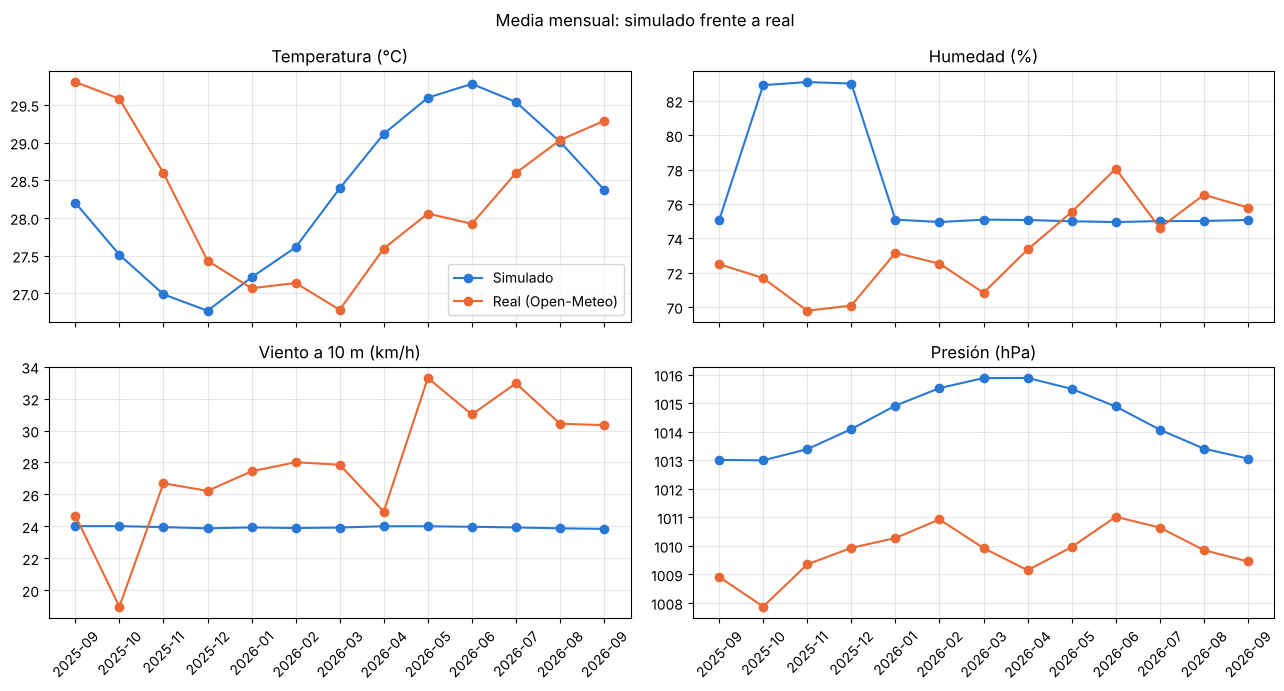

In [13]:
mes = cruce["timestamp"].dt.strftime("%Y-%m")

fig, ejes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for eje, (sim, rea, nombre) in zip(ejes.flat, PARES):
    mensual = cruce.groupby(mes)[[sim, rea]].mean()
    eje.plot(mensual.index, mensual[sim], color=AZUL, marker="o", label="Simulado")
    eje.plot(mensual.index, mensual[rea], color=NARANJA, marker="o", label="Real (Open-Meteo)")
    eje.set_title(nombre)
    eje.tick_params(axis="x", rotation=45)
    eje.grid(alpha=0.3)
ejes[0, 0].legend()
fig.suptitle("Media mensual: simulado frente a real")
guardar(fig, "03_simulado_vs_real_mensual")

La gran diferencia está en la estacionalidad. El viento real cambia mucho durante el año: es más flojo en octubre (unos 19 km/h) y muy fuerte de mayo a julio (más de 30 km/h). El simulado es prácticamente igual todos los meses, unos 24 km/h.

La temperatura también tiene los meses cambiados: en los datos simulados los más calurosos son mayo y junio, y en los reales septiembre y octubre.

La humedad simulada sube de golpe unos 8 puntos de octubre a diciembre y el 1 de enero vuelve de un día para otro al 75 %. Coincide con la temporada de lluvias, así que suponemos que se simuló como un escalón. En la simulación además llueve unas tres veces más que en la realidad (1.150 mm al año frente a 370).

La presión sale unos 4–5 hPa más alta, pero eso es porque se miden cosas distintas: nuestras lecturas están a nivel del mar y Open-Meteo da la presión en superficie.

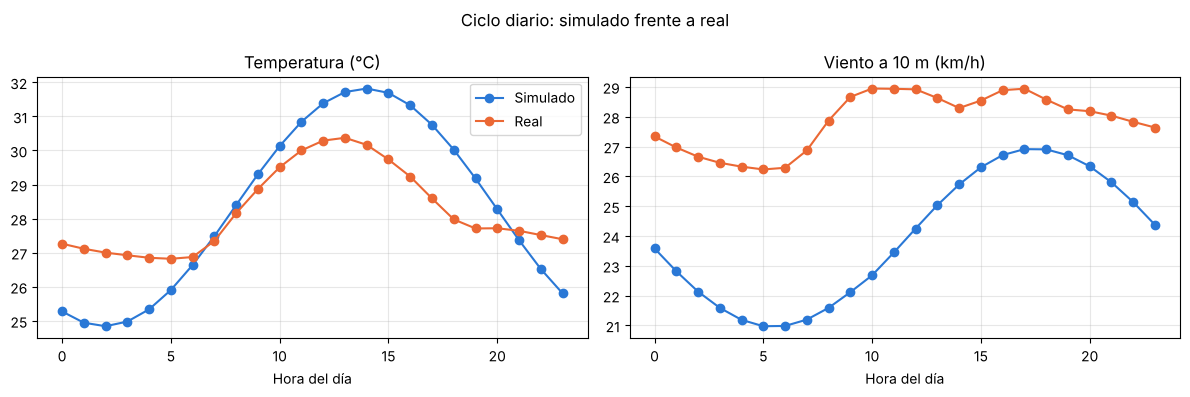

In [14]:
hora = cruce["timestamp"].dt.hour

fig, (e1, e2) = plt.subplots(1, 2, figsize=(12, 4))
for eje, (sim, rea, nombre) in zip((e1, e2), [PARES[0], PARES[2]]):
    diario = cruce.groupby(hora)[[sim, rea]].mean()
    eje.plot(diario.index, diario[sim], color=AZUL, marker="o", label="Simulado")
    eje.plot(diario.index, diario[rea], color=NARANJA, marker="o", label="Real")
    eje.set_title(nombre)
    eje.set_xlabel("Hora del día")
    eje.grid(alpha=0.3)
e1.legend()
fig.suptitle("Ciclo diario: simulado frente a real")
guardar(fig, "03_simulado_vs_real_diario")

En el día tipo se parecen más: la temperatura simulada sube y baja a las mismas horas que la real, aunque con más diferencia entre el día y la noche, y el viento real también es más fuerte por la tarde, solo que con una media más alta.

Es decir, los datos simulados reproducen bien el ciclo diario pero no lo que pasa a lo largo del año. Instante a instante, el viento simulado y el real prácticamente no se parecen (correlación de 0,06).

## 4. Lo que falta

- 4.1 Validación con la producción eólica real de WEB Aruba (27–28 de diciembre de 2025)
- 4.2 Distribución del target y factor de capacidad
- 4.3 Ciclo diario y mensual del target
- 4.4 Correlación de las entradas con el target a 1 hora
- 4.5 Autocorrelación del target
- 4.6 Conclusiones del EDA